In [ ]:
%pip install geopandas py7zr -q

StatementMeta(, ba54ad7e-a318-41f7-87db-7bd930f39a6c, 13, Finished, Available, Finished, True)


Note: you may need to restart the kernel to use updated packages.


StatementMeta(, ba54ad7e-a318-41f7-87db-7bd930f39a6c, 15, Finished, Available, Finished, False)

Archive téléchargée


12 communes TPM | 16 arrondissements Marseille
Fichier utilisé : /lakehouse/default/Files/cartes/iris_brut/CONTOURS-IRIS_3-0__SHP__FRA_2023-01-01/CONTOURS-IRIS/1_DONNEES_LIVRAISON_2024-02-00238/CONTOURS-IRIS_3-0_SHP_LAMB93_FXX-ED2023-01-01/CONTOURS-IRIS.shp


ville
marseille    393
toulon       176
Name: count, dtype: int64
Sauvegardé


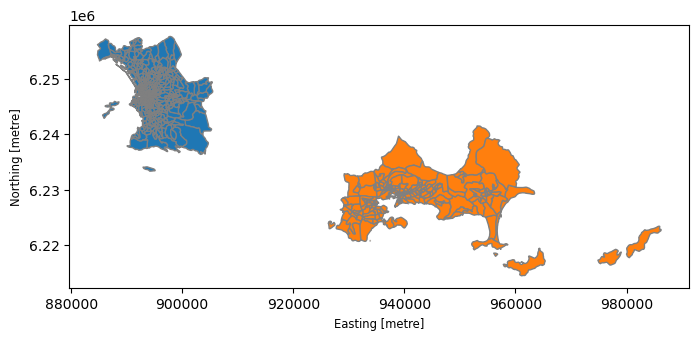

In [ ]:
import geopandas as gpd, requests, py7zr, glob, os

# ---------- Paramètres ----------
URL_IRIS = "https://data.geopf.fr/telechargement/download/CONTOURS-IRIS/CONTOURS-IRIS_3-0__SHP__FRA_2023-01-01/CONTOURS-IRIS_3-0__SHP__FRA_2023-01-01.7z"
BASE = "/lakehouse/default/Files/cartes"
DOSSIER_BRUT = f"{BASE}/iris_brut"
os.makedirs(DOSSIER_BRUT, exist_ok=True)

# ---------- 1. Télécharger et décompresser l'archive IGN ----------
archive = f"{DOSSIER_BRUT}/contours_iris.7z"
if not os.path.exists(archive):
    with requests.get(URL_IRIS, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(archive, "wb") as f:
            for morceau in r.iter_content(chunk_size=1024 * 1024):
                f.write(morceau)
    print("Archive téléchargée")

with py7zr.SevenZipFile(archive) as z:
    z.extractall(DOSSIER_BRUT)

# ---------- 2. Liste des communes des 2 villes ----------
communes_tpm = requests.get("https://geo.api.gouv.fr/epcis/248300543/communes", timeout=60).json()
CODES_TOULON = [c["code"] for c in communes_tpm]
CODES_MARSEILLE = [str(code) for code in range(13201, 13217)]   # 16 arrondissements
print(len(CODES_TOULON), "communes TPM |", len(CODES_MARSEILLE), "arrondissements Marseille")

# ---------- 3. Lire et filtrer les IRIS (France métropolitaine uniquement) ----------
shp = [s for s in glob.glob(f"{DOSSIER_BRUT}/**/*.shp", recursive=True)
       if "IRIS" in s.upper() and "FXX" in s.upper()][0]
print("Fichier utilisé :", shp)
iris = gpd.read_file(shp).to_crs(2154)

com_col = [c for c in iris.columns if c.upper() in ("INSEE_COM", "CODE_INSEE", "INSEE_COMM")][0]
iris["ville"] = None
iris.loc[iris[com_col].isin(CODES_TOULON), "ville"] = "toulon"
iris.loc[iris[com_col].isin(CODES_MARSEILLE), "ville"] = "marseille"
iris = iris[iris["ville"].notna()]
print(iris["ville"].value_counts())

# ---------- 4. Sauvegarder ----------
iris.to_parquet(f"{BASE}/iris_toulon_marseille.parquet")
iris.plot(column="ville", figsize=(8, 8), edgecolor="grey")
print("Sauvegardé")